# Task 3: technical evaluation of saving guidance
Gumar Nurtore and Kydyralina Akniet. Synthetic input profiles; real execution timings.

**Question:** How much time does personalized arithmetic add to a generic reminder?
The methods have different outputs. We do not test an LLM or real student behavior.
Seed: 3242. One observation is a whole batch of 10, 100 or 330 profiles.


In [1]:
from pathlib import Path
import sys
ROOT = Path.cwd()
if not (ROOT / "src").exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))
import json
import pandas as pd
from IPython.display import display, Image
from src.process_data import load_logs, summarize
from src.visualize import make_figures
from src.task3_report import write_reports
logs = load_logs()
print("Raw rows:", len(logs))
display(logs.groupby(["phase", "method", "load"]).size().rename("n").to_frame())

Raw rows: 1320


n
phase     method   load     
benchmark Baseline 10    200
                   100   200
                   330   200
          Proposed 10    200
                   100   200
                   330   200
warmup    Baseline 10     20
                   100    20
                   330    20
          Proposed 10     20
                   100    20
                   330    20

## 1. Warm-up filtering
Exclude the 20 warm-up batches per configuration by the saved phase label, not by removing slow observations. Keep all measured attempts for the error-rate denominator. Successful-batch latencies are summarized separately.

In [2]:
measured = logs[logs.phase == "benchmark"].copy()
print("Excluded warm-up:", len(logs)-len(measured))
print("Measured attempts:", len(measured), "Failures:", int((~measured.ok).sum()))
assert len(measured) == 1200
assert measured.groupby(["method","load"]).size().eq(200).all()

Excluded warm-up: 120
Measured attempts: 1200 Failures: 0


## 2. Statistics
The module calculates median, quartiles, mean, sample SD, p95 and p99. It resamples each configuration's successful timings 2000 times and takes the 2.5th and 97.5th percentiles of bootstrap medians. The seed fixes the resampling. CIs apply only to these recorded runs; p99 is unstable with 200 measurements. Timings from new runs will differ.

In [3]:
summary = summarize(logs, seed=3242, bootstrap_samples=2000)
summary.to_csv(ROOT / "data/processed/metrics_summary.csv", index=False)
display(summary.round(6))

,load,method,attempts,successes,errors,error_rate,mean_ms,sd_ms,median_ms,p25_ms,p75_ms,p95_ms,p99_ms,ci_low_ms,ci_high_ms
0,10,Baseline,200,200,0,0.0,0.006017,0.006118,0.00450,0.002075,0.007425,0.015425,0.023713,0.00420,0.00470
1,10,Proposed,200,200,0,0.0,0.020698,0.007831,0.01780,0.015700,0.023900,0.033245,0.047037,0.01715,0.01905
2,100,Baseline,200,200,0,0.0,0.012670,0.007828,0.01065,0.007700,0.016350,0.021525,0.034927,0.01035,0.01110
3,100,Proposed,200,200,0,0.0,0.158784,0.151912,0.13420,0.123925,0.151025,0.223150,0.374752,0.13045,0.13970
4,330,Baseline,200,200,0,0.0,0.034054,0.051061,0.02600,0.022875,0.033450,0.051935,0.078646,0.02515,0.02800
5,330,Proposed,200,200,0,0.0,0.469154,0.121203,0.42910,0.402125,0.483475,0.700840,0.867709,0.41340,0.44020


## 3. Figures
The line chart shows medians and 95% bootstrap intervals. The boxplot shows quartiles, 1.5-IQR whiskers and individual outliers, with separate median confidence intervals. Color and marker shape distinguish methods. All exports are PDF and 300 DPI PNG. Log axes make the small baseline times readable.

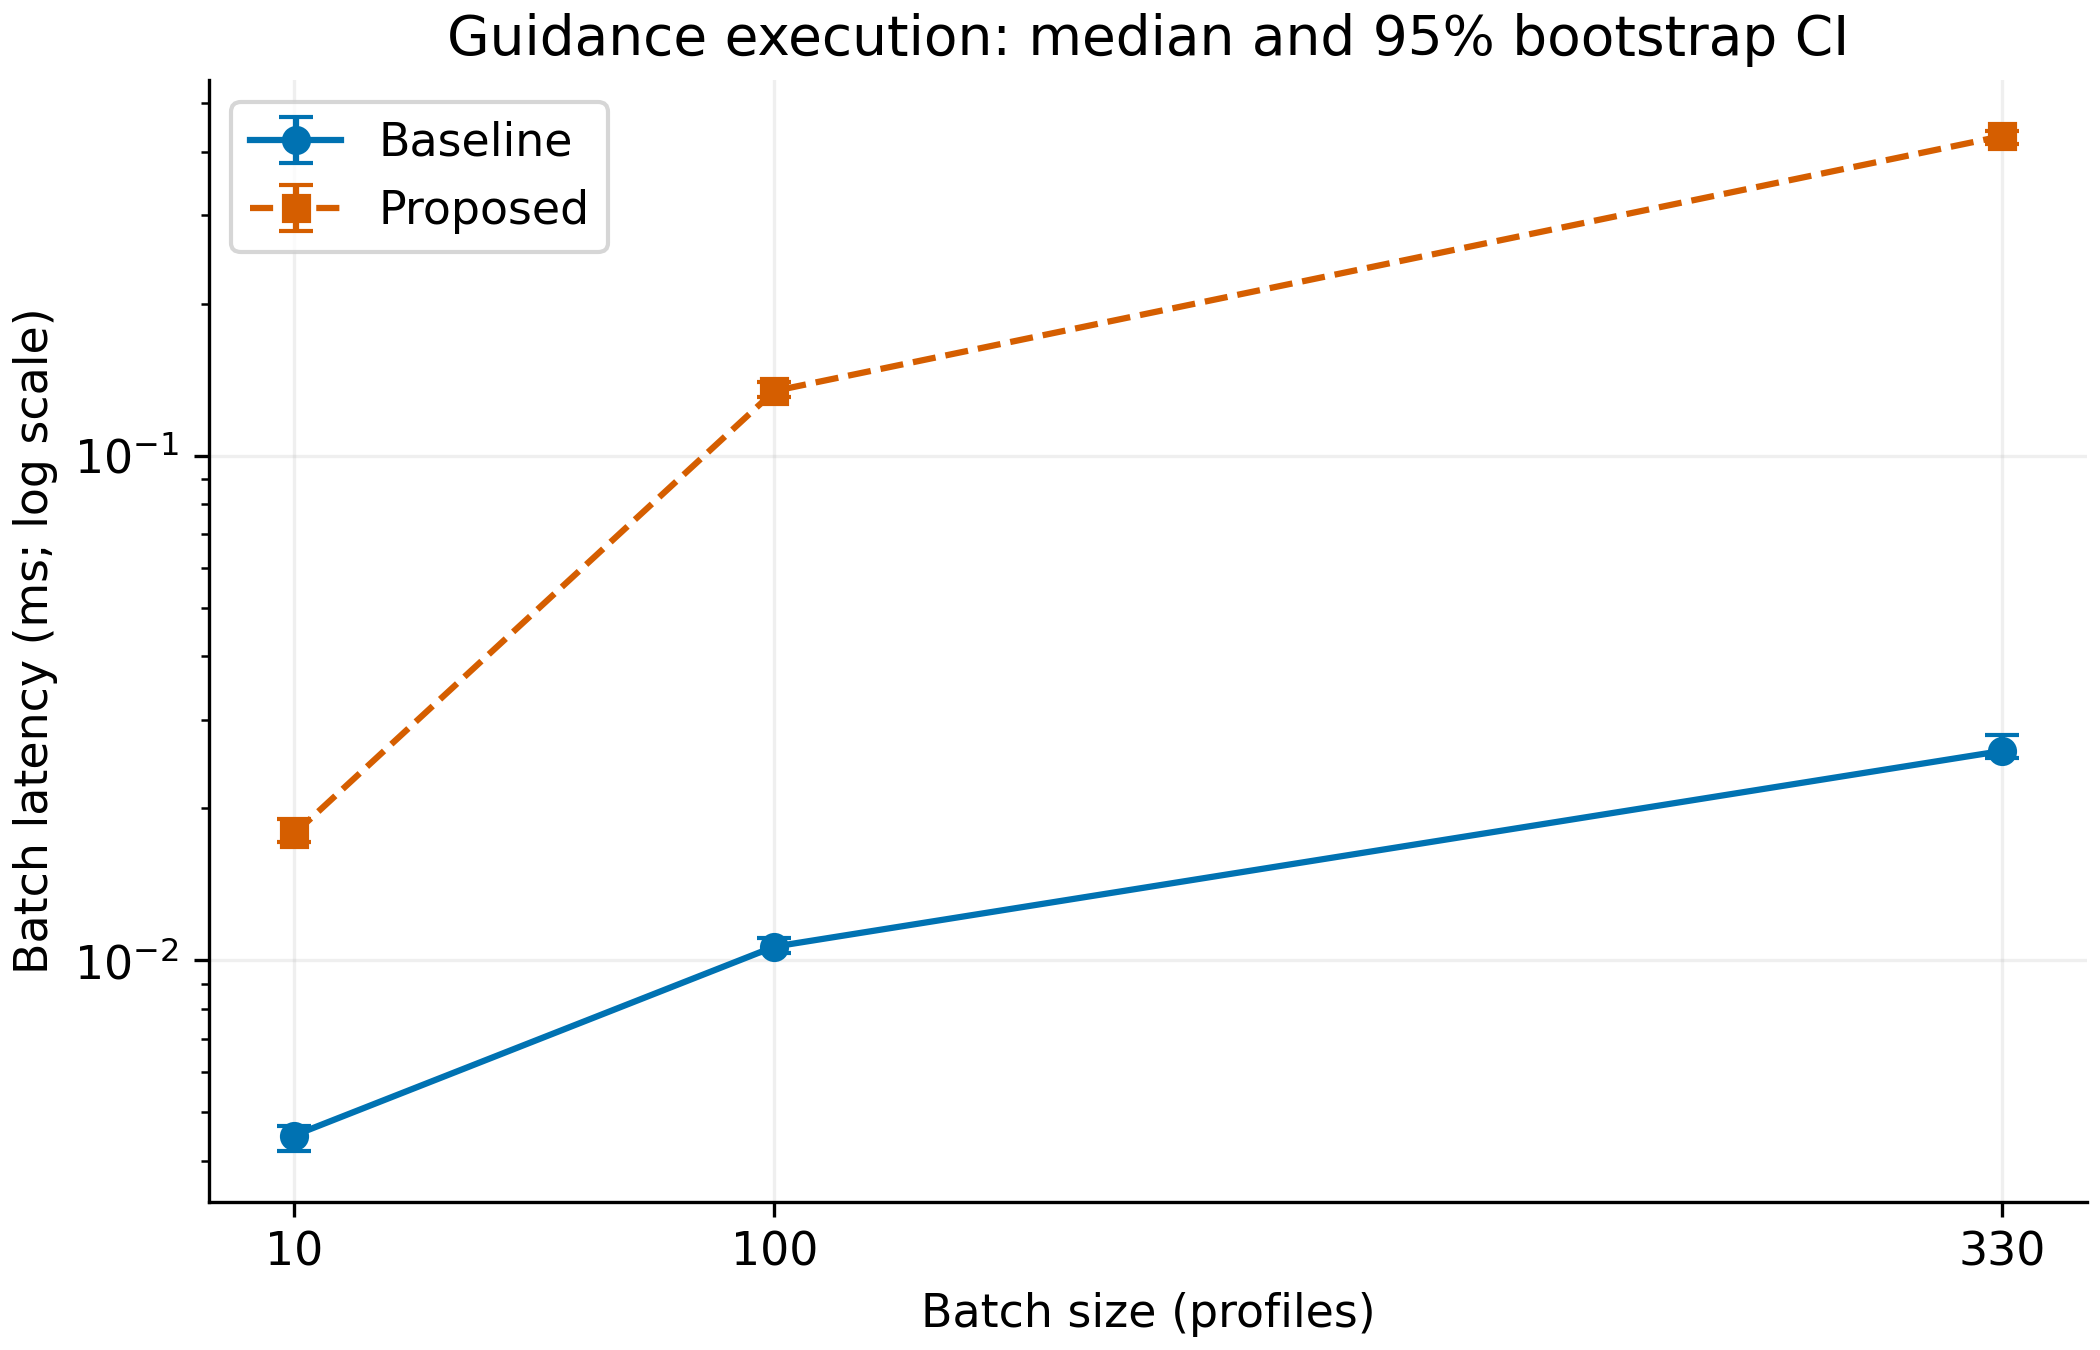

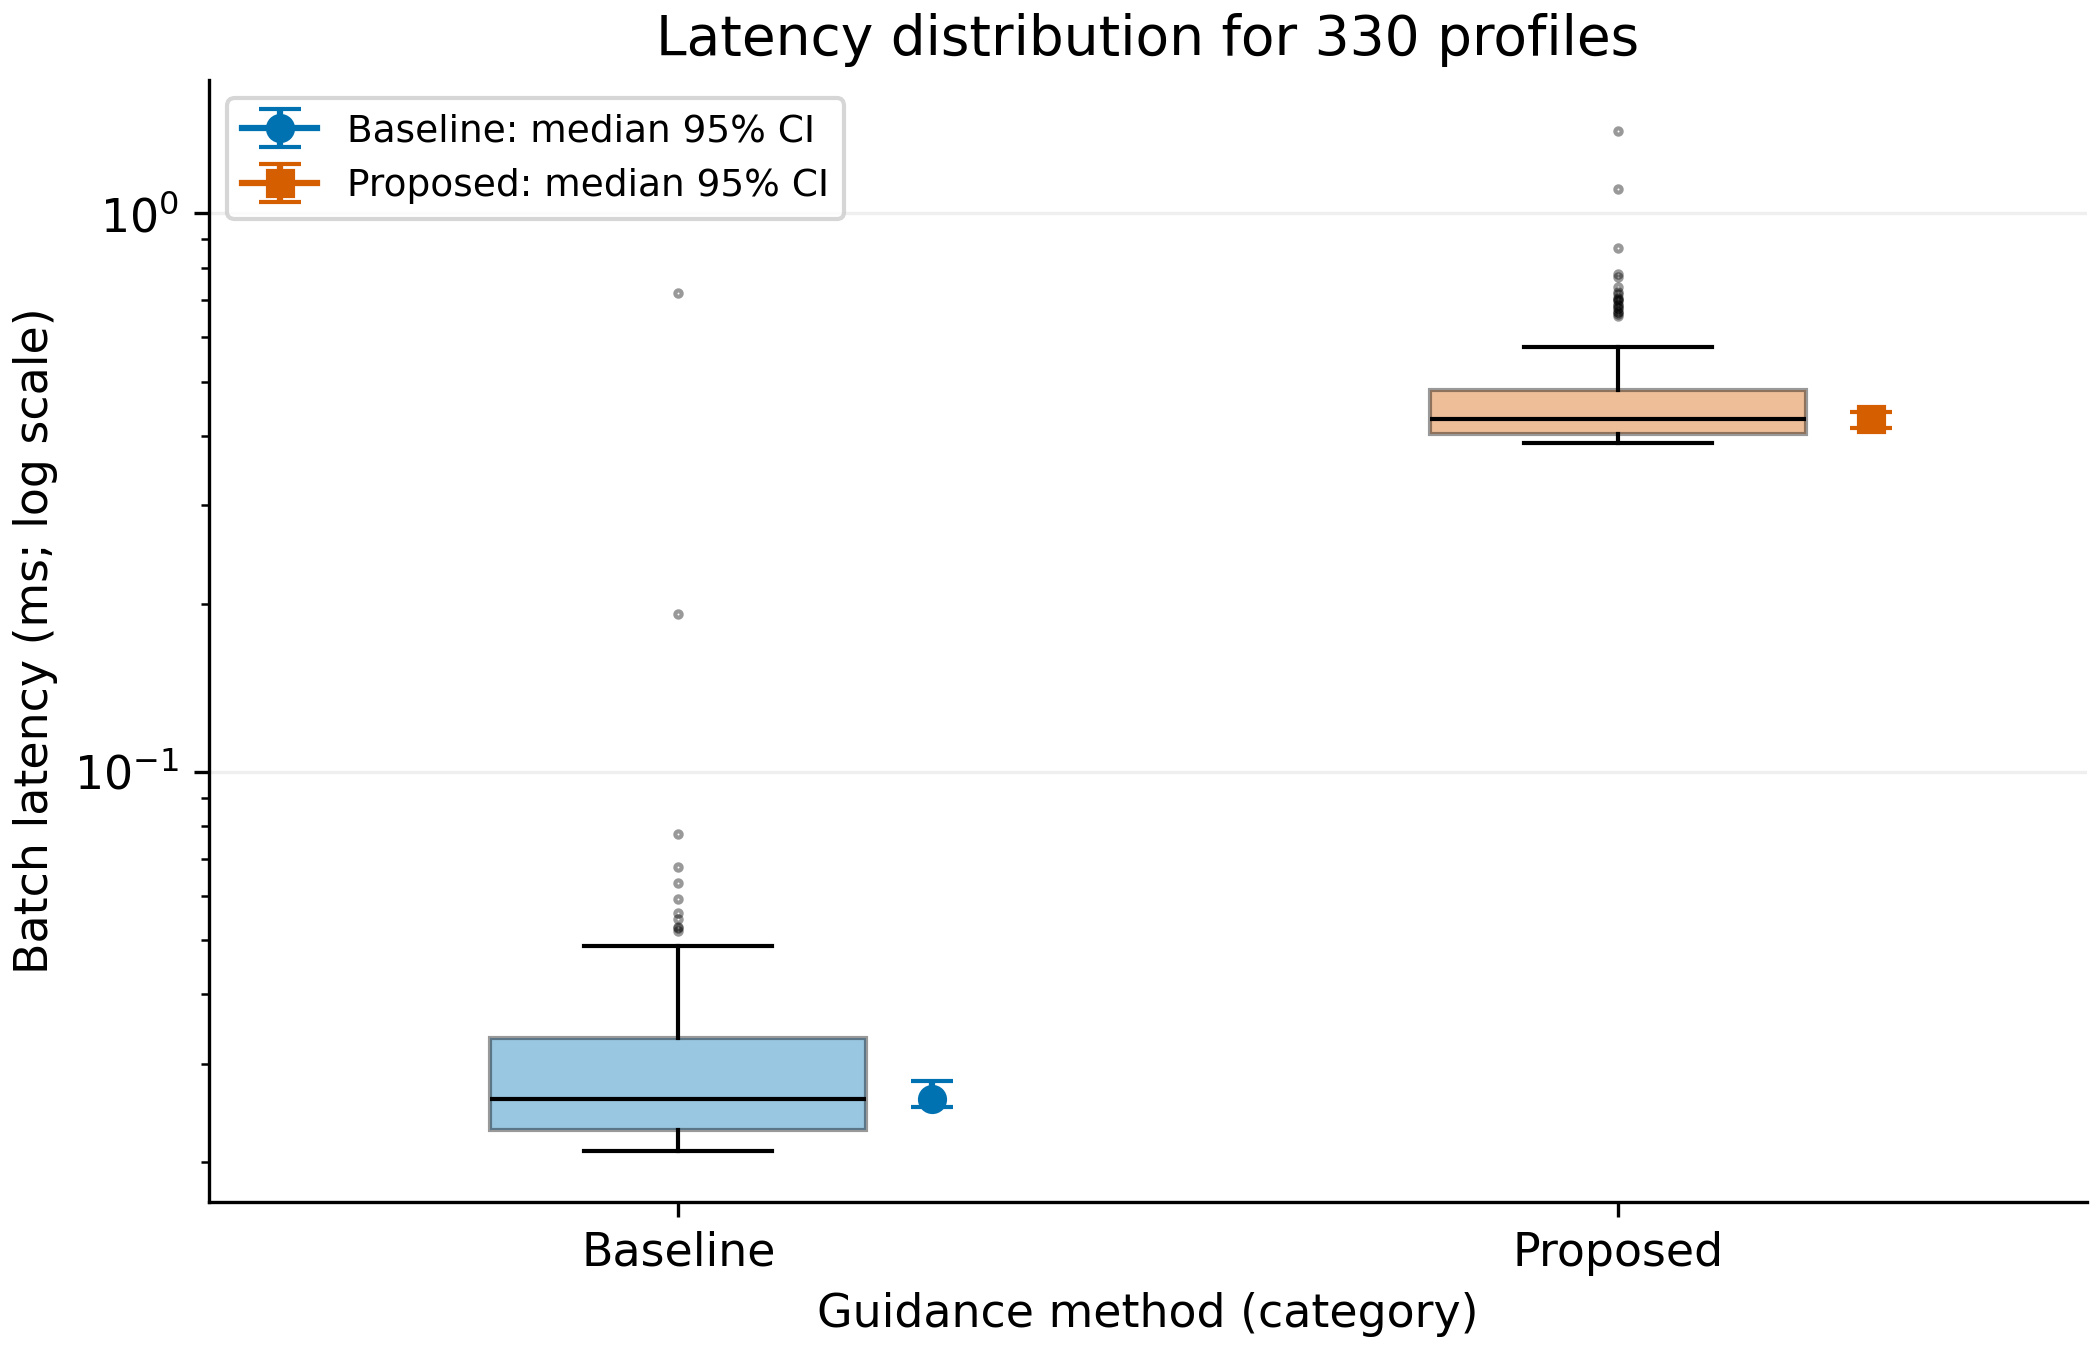

In [4]:
make_figures(logs, summary)
for name in ["fig1_latency_vs_load", "fig2_distribution_boxplot"]:
    display(Image(filename=str(ROOT / f"reports/figures/{name}.png"), width=760))

## 4. Synthetic survey: pipeline demonstration only
These 330 records are program-generated scenarios. Assignment A/B/C and post-treatment answers were simulated. The C-minus-B score difference is a property of the generator, not evidence about real people. No hypothesis test on human effectiveness is claimed.

In [5]:
survey = pd.read_csv(ROOT / "data/synthetic/synthetic_responses_330.csv")
assert survey.participant_id.is_unique and survey.data_origin.eq("synthetic").all()
survey_summary = survey.groupby("group").agg(n=("participant_id","size"), mean_goal_change=("goal_change","mean"), mean_purchase_intention=("purchase_intention_post","mean"))
survey_summary.to_csv(ROOT / "data/processed/synthetic_survey_summary.csv")
display(survey_summary.round(3))
print("Synthetic C minus B:", round(survey_summary.loc["C","mean_goal_change"]-survey_summary.loc["B","mean_goal_change"],3), "scale points; NOT a real treatment effect")

,n,mean_goal_change,mean_purchase_intention
group,,,
A,110,-0.282,4.045
B,110,-0.064,3.909
C,110,0.064,3.664


Synthetic C minus B: 0.127 scale points; NOT a real treatment effect


## 5. Discussion and report
Personalized arithmetic needs additional CPU work. Zero observed errors means that the measured valid-input batches passed the implemented checks. It does not establish universal correctness or clinical/financial suitability. A real study would need voluntary student responses and a tested intervention. The next cell refreshes the submission report and README from the same saved metrics.

In [6]:
write_reports(summary, survey_summary)
print("Saved reports/task3_report.md and README.md")
metadata = json.loads((ROOT / "data/raw/run_metadata.json").read_text())
print("Measurement environment:", metadata["execution_location"])
print("Measurement date (UTC):", metadata["started_utc"])
print("Python:", metadata["python"].split()[0])

Saved reports/task3_report.md and README.md
Measurement environment: ChatGPT execution environment, not student laptop
Measurement date (UTC): 2026-11-05T15:13:55.487570+00:00
Python: 3.12.10
